# =============================================================

 # <center> Tesla Stock Webscraping
 # Author: Hassan Mukhtar
 # Tools : Python, Pandas, NumPy, Matplotlib, BeautifulSoup </center>

# =============================================================

In [16]:
import pandas as pd
import requests
from bs4 import BeautifulSoup

In [17]:
import yfinance as yf

## Use yfinance to Extract Stock Data


In [18]:
# ticker function to extract data
tesla = yf.Ticker("TSLA")

In [19]:
# save the data in dataframe with max amount of time
tesla_data = tesla.history(period="max")

In [20]:
tesla_data.reset_index(inplace=True)
tesla_data.head()

,Date,Open,High,Low,Close,Volume,Dividends,Stock Splits
0,2010-06-29 00:00:00-04:00,1.266667,1.666667,1.169333,1.592667,281494500,0.0,0.0
1,2010-06-30 00:00:00-04:00,1.719333,2.028000,1.553333,1.588667,257806500,0.0,0.0
2,2010-07-01 00:00:00-04:00,1.666667,1.728000,1.351333,1.464000,123282000,0.0,0.0
3,2010-07-02 00:00:00-04:00,1.533333,1.540000,1.247333,1.280000,77097000,0.0,0.0
4,2010-07-06 00:00:00-04:00,1.333333,1.333333,1.055333,1.074000,103003500,0.0,0.0



## Use Webscraping to Extract Tesla Revenue Data


In [21]:
URL = "https://cf-courses-data.s3.us.cloud-object-storage.appdomain.cloud/IBMDeveloperSkillsNetwork-PY0220EN-SkillsNetwork/labs/project/revenue.htm"


In [22]:
# send http request to the webpage
html_data = requests.get(URL).text

In [23]:
#create a beautifulsoup object to parse the data with parser
soup = BeautifulSoup(html_data , "html.parser")

In [24]:
# create DataFrame for storing data
tesla_revenue = pd.DataFrame(columns=["Date", "Revenue"])
for row in soup.find_all("tbody")[1].find_all("tr"):
    col = row.find_all("td")
    if len(col) == 2:
        date = col[0].text
        revenue = col[1].text
        tesla_revenue = pd.concat([tesla_revenue,
                                   pd.DataFrame({"Date": [date],
                                                 "Revenue": [revenue]})],
                                  ignore_index=True)

In [25]:
# remove the comma and dollar sign
tesla_revenue["Revenue"] = tesla_revenue['Revenue'].str.replace(',|\$',"",regex=True)

In [26]:
# remove null or empty values
tesla_revenue.dropna(inplace=True)

tesla_revenue = tesla_revenue[tesla_revenue['Revenue'] != ""]

In [27]:
# top 5 rows
tesla_revenue.head()

,Date,Revenue
0,2022-09-30,21454
1,2022-06-30,16934
2,2022-03-31,18756
3,2021-12-31,17719
4,2021-09-30,13757


In [28]:
# bottom rows
tesla_revenue.tail()

,Date,Revenue
48,2010-09-30,31
49,2010-06-30,28
50,2010-03-31,21
52,2009-09-30,46
53,2009-06-30,27


## Plot Tesla Stock Graph

In [29]:
import matplotlib.pyplot as plt

def make_graph(stock_data, revenue_data, stock):
    stock_data_specific = stock_data[stock_data.Date <= '2021-06-14']
    revenue_data_specific = revenue_data[revenue_data.Date <= '2021-04-30']

    fig, axes = plt.subplots(2, 1, figsize=(12, 8), sharex=True)

    # Stock price
    axes[0].plot(pd.to_datetime(stock_data_specific.Date), stock_data_specific.Close.astype("float"), label="Share Price", color="blue")
    axes[0].set_ylabel("Price ($US)")
    axes[0].grid(True, axis='y')
    axes[0].set_title(f"{stock} - Historical Share Price")

    # Revenue
    axes[1].plot(pd.to_datetime(revenue_data_specific.Date), revenue_data_specific.Revenue.astype("float"), label="Revenue", color="green")
    axes[1].set_ylabel("Revenue ($US Millions)")
    axes[1].set_xlabel("Date")
    axes[1].grid(True, axis='y')
    axes[1].set_title(f"{stock} - Historical Revenue")
    
    plt.tight_layout()
    plt.show()

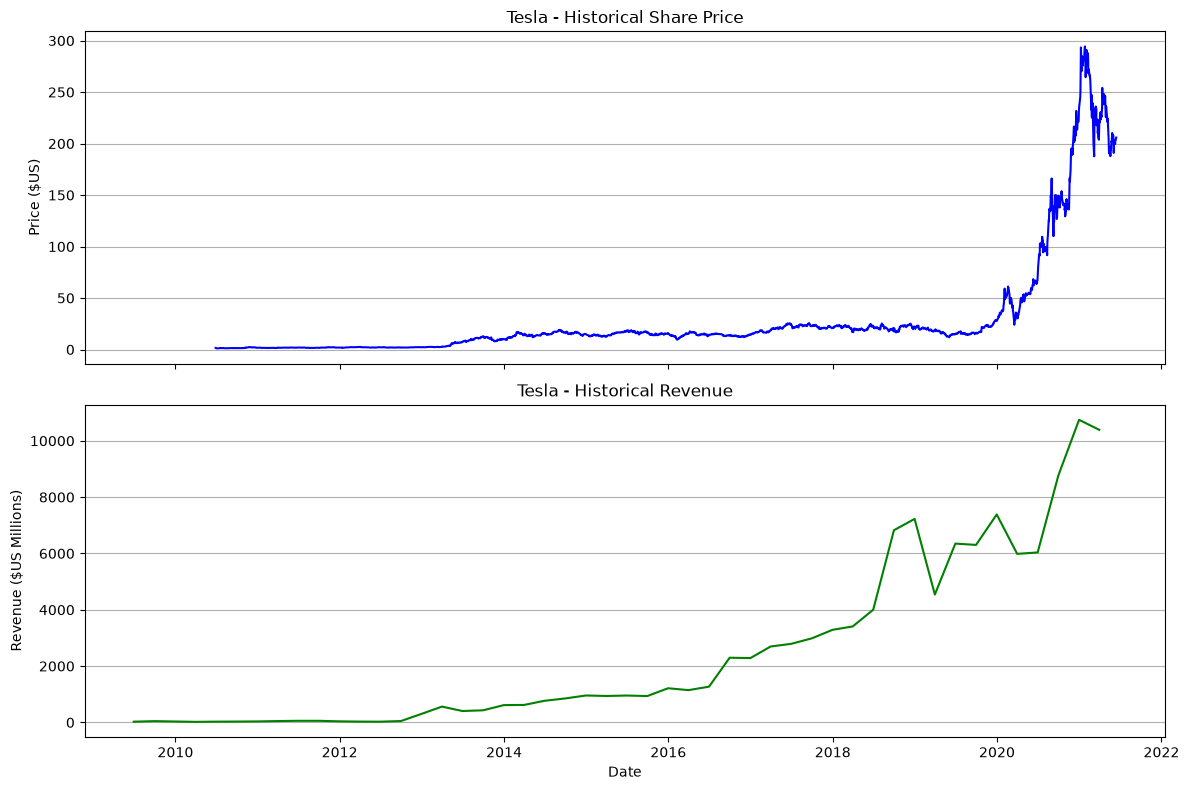

In [30]:
make_graph(tesla_data, tesla_revenue, 'Tesla')